# ✨ **Polynomial Regression in Data Science**

#### ➡️ Polynomial Regression is an extension of **Linear Regression**. It allows us to **model non-linear relationships between the independent variable(s) 𝑋 and the dependent variable 𝑌 by introducing polynomial terms**.

#### ➡️ Also -> Polynomial Regression is a regression algorithm that models the realationship between dependent (y) and independent variable(x) as nth degree polynomial

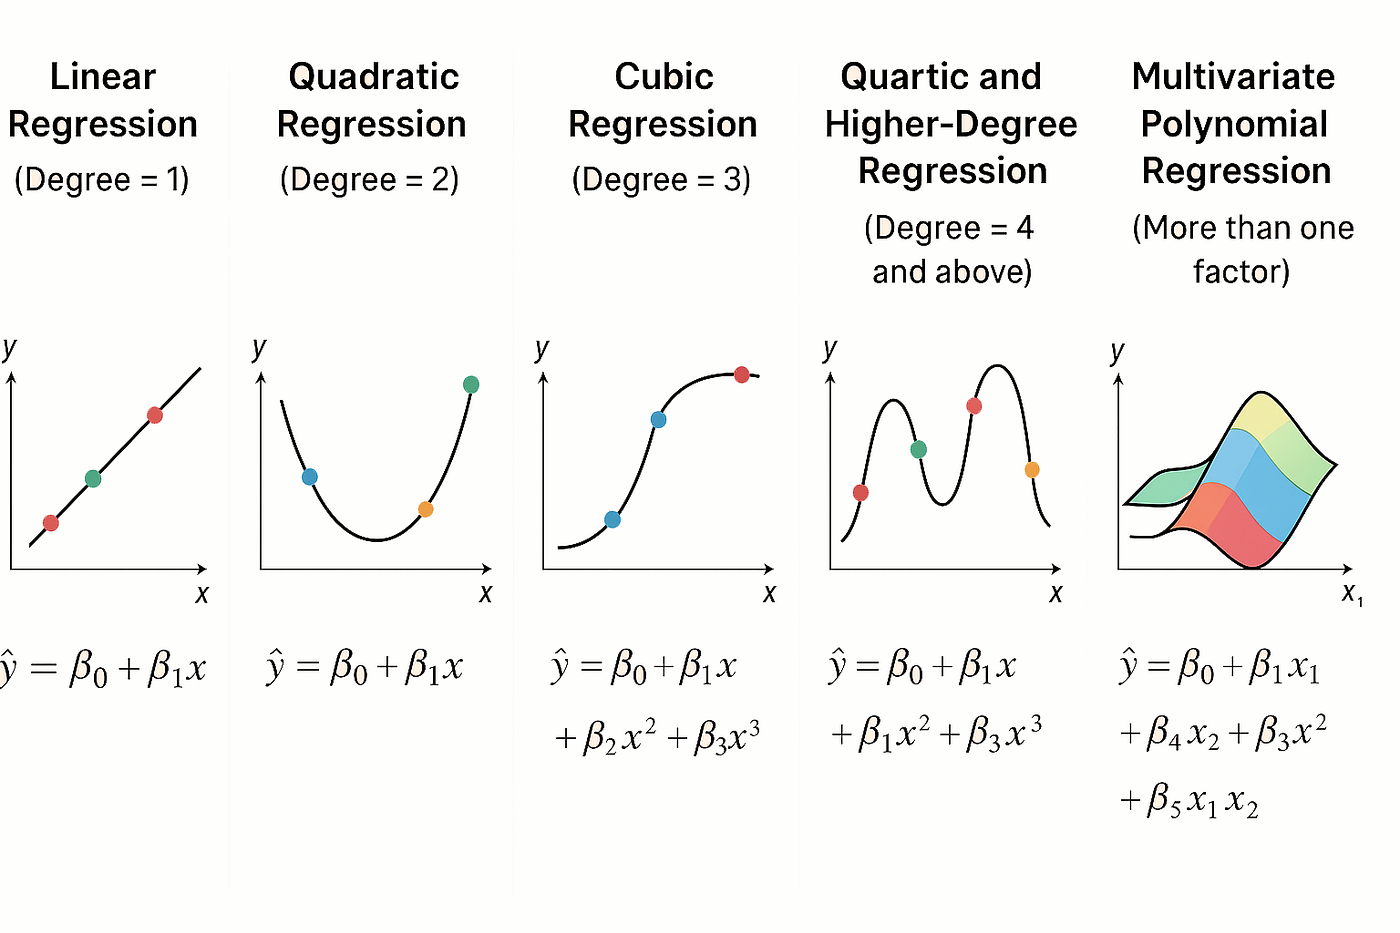

<hr>




## 1️⃣ When to use Polynomial Regression

We use Polynomial Regression when:

- The data shows a **curved relationship** (non-linear) rather than a straight line.

- Linear regression underfits the data.

- You want to **capture more complexity in relationships without moving to more complex models like neural networks.**

Example: Predicting the growth of a plant over time might not be linear; initially, it grows slowly, then rapidly, then plateaus.

<br>
<hr>


## 2️⃣ Mathematical Formulation

For a simple case with one feature \(X\):

**Linear Regression equation:**

$$
Y = \beta_0 + \beta_1 X + \epsilon
$$

**Polynomial Regression equation (degree \(d\)):**

$$
Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \beta_3 X^3 + \dots + \beta_d X^d + \epsilon
$$

Where:

- $(\beta_0, \beta_1, \dots, \beta_d)$ are **coefficients**.
- $(d)$ is the **degree** of the polynomial (how curved the fit is).
- $(\epsilon)$ is the **error term**.

💡 Key idea: Polynomial regression is still **linear in the coefficients**, even though it’s non-linear in the feature $(X)$.

<br>
<hr>

## 3️⃣ **Assumption in Polynomial Regression**

| Assumption              | What It Is                                              | Consequence if Violated                 | How to Check in Python                |
| ----------------------- | ------------------------------------------------------- | --------------------------------------- | ------------------------------------- |
| Linearity of Parameters | Model linear in coefficients (β's)                      | N/A (still valid if nonlinear in X)     | PolynomialFeatures + LinearRegression |
| Independence of Errors  | Residuals are independent                               | Biased standard errors                  | Durbin-Watson test                    |
| Homoscedasticity        | Constant variance of residuals                          | Wrong standard errors                   | Residual plot                         |
| Normality of Errors     | Residuals are normally distributed                      | Incorrect confidence intervals/p-values | Histogram, Q-Q plot                   |
| No Multicollinearity    | Features not highly correlated                          | Unstable coefficients                   | VIF                                   |
| Correct Specification   | Model includes all relevant predictors & correct degree | Underfitting/Overfitting                | Cross-validation                      |


## 4️⃣ **Steps to perform Polynomial Regression**

### ➡️ **Step 1: Import Necessary Libraries and Load Dataset**

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:

df = pd.read_csv("Economy of Scale.csv")
df.head()

,Units,Cost
0,1.0,95.1
1,1.2,96.5
2,1.2,73.7
3,1.2,95.6
4,1.3,98.8


In [7]:
df.describe()

,Units,Cost
count,1000.000000,1000.000000
mean,4.471500,40.053200
std,1.336437,10.596183
min,1.000000,20.000000
25%,3.600000,32.900000
50%,4.400000,38.300000
75%,5.300000,44.525000
max,10.000000,100.000000


### ➡️ Step 2: **Checking the Linearity Relationship between dependent and independent variable of the data**

**After plotting the scatter plot interpretation : x and y exhibits the polynomial Relationship**

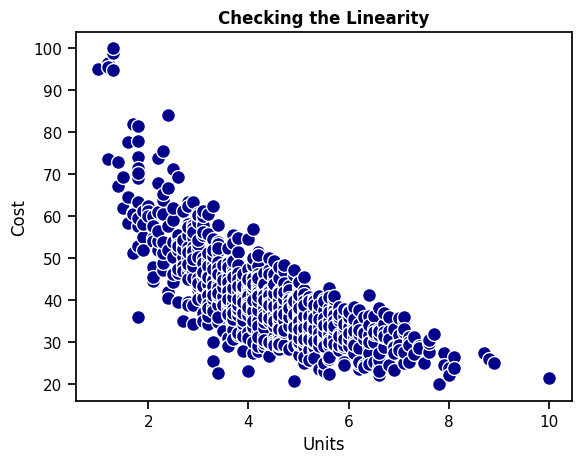

In [8]:
# sns.set_style("whitegrid")
sns.set_context("notebook")


sns.scatterplot(
    x = "Units",
    y = "Cost",
    data = df,
    marker = 'o',
    # alpha = 0.6,
    s = 100, #for the size of the markers
    color = 'darkblue',
    linewidth  = 1,
    edgecolor = "white"
    )

x = df["Units"] 
y = df["Cost"]

plt.title("Checking the Linearity", fontweight = 'bold')

plt.show() #underfitting line of linear regression will form if we use the linear regression instead of polynomial regression

### 🌟🌟🌟 NOTE FOR ABOVE PLOT : **Interpretain of the Graph**

➡️ **Plot shows the underfitting nature of linear regression**

The scatter plot shows a **non-linear, inverse relationship** between **Units (x-axis)** and **Cost (y-axis)**.

---

#### **Data Pattern**
- The data forms a **curved, decaying trend**, indicating a **non-linear relationship** — likely **polynomial**, **exponential**, or **power-law** in nature.

---

#### **Economic Insight**
This shape reflects **diminishing marginal costs** or **economies of scale**, where:
- Early units are costly.
- Cost per unit **drops quickly** as production increases.
- The curve **flattens** as costs stabilize.

---

#### **Red Line (Linear Model)**
- The red line **fails to Capture the Pattern (High Bias)**
- The data has a **distinct decaying curve** (a non-linear shape), which the **straight red line** fails to follow. The line essentially **misses the pattern** of the data — a characteristic known as **high bias**.

---

#### **Observations**
- The line **severely overestimates** the **Cost** in the **middle range** of Units (≈ 3 to 7).  
- It **underestimates** the **Cost** at the **low end** (Units < 2).  
- It **slightly underestimates** the **Cost** at the **high end** (Units > 8).


---

#### **Underfitting Observation**
- A **linear model** would **underfit** this data since it cannot capture the clear curvature.
- Most points would deviate significantly from the fitted line.

---

#### **Modeling Conclusion**
- A **Polynomial Regression** or another **non-linear model** is better suited to represent this relationship accurately and produce reliable predictions.



### 🌟🌟🌟 Underfitting and Overfitting in short

| **Concept**      | **Description** | **Model Appearance on Graph** | **Recommended Action** |
|------------------|-----------------|-------------------------------|-------------------------|
| **Underfitting** | The model is too simple (**high bias**) and fails to capture the underlying trend. | The line/curve is too straight or does not follow the shape of the data points. | Increase model complexity (e.g., use **Polynomial Regression**). |
| **Overfitting**  | The model is too complex (**high variance**) and fits the noise/random fluctuations in the training data, not just the trend. | The line/curve wiggles excessively, passing through or very close to almost every data point. | Decrease model complexity (e.g., lower the polynomial degree) or use **Regularization**. |

<br>
<hr>

In [9]:
#Even R2_Score tells the same thing that this data is not fit for linear regression

from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(df[["Units"]],df["Cost"])

y_pred = lr.predict(df[["Units"]])

lr.score(df[["Units"]],df["Cost"])

0.5785681557941996

🧠 **Interpreting $R^2$**
| **R² Value** | **Interpretation**                         |
| ------------ | ------------------------------------------ |
| 0.0 → 0.3    | Weak model — underfitting                  |
| 0.3 → 0.7    | Moderate fit                               |
| 0.7 → 0.9    | Good fit                                   |
| 0.9 → 1.0    | Excellent fit — but check for overfitting! |


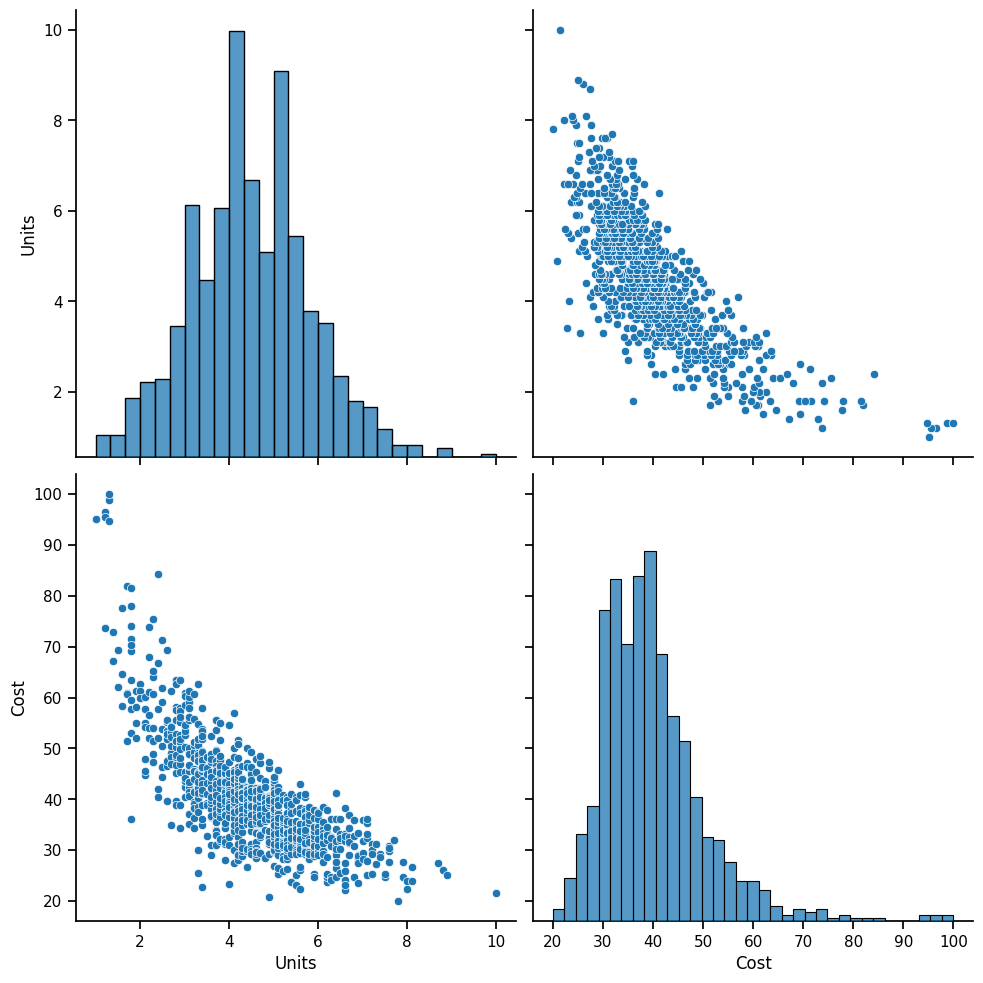

In [10]:

sns.pairplot(df, height = 5) # size parameter has changed to height
plt.show()

<Axes: ylabel='Units'>

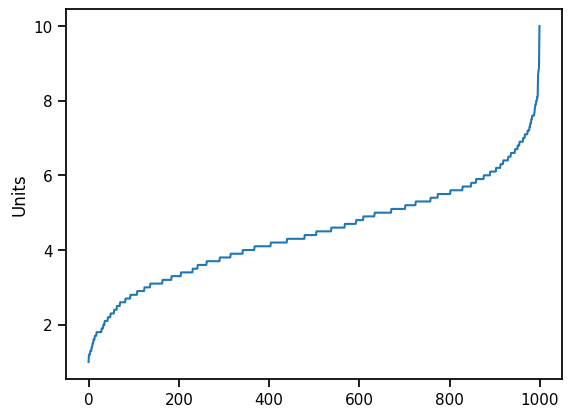

In [11]:
sns.lineplot(data = df["Units"])

<Axes: ylabel='Cost'>

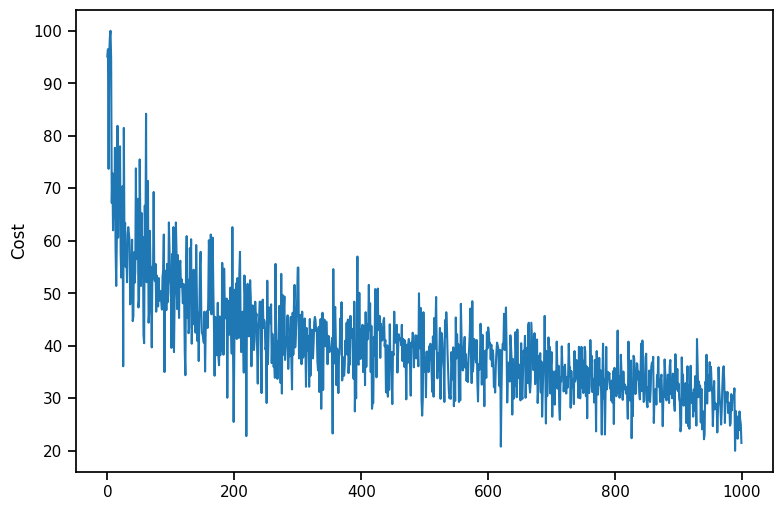

In [12]:
plt.figure(figsize = (9,6))
sns.lineplot(data = df["Cost"])

### ➡️ **Step 3: Transform features into polynomial features**

➡️ since variables of data show polynomial relation we need to convert the feaures into polynomial features

**Example**

```python
# Degree 2 polynomial
poly_features = PolynomialFeatures(degree=2)
X_poly = poly_features.fit_transform(X)

```
**Explanation**

- `degree=2` → creates $( X )$ and $( X^2 )$ terms.  
- `fit_transform()` → computes and transforms $( X )$ into polynomial terms.  

Now, $( X_{\text{poly}} )$ looks like:

$$
\begin{bmatrix}
1 & 1 & 1 \\
1 & 2 & 4 \\
1 & 3 & 9 \\
1 & 4 & 16 \\
1 & 5 & 25 \\
1 & 6 & 36
\end{bmatrix}
$$

Where columns are: `[1, X, X^2]`.



In [13]:
from sklearn.preprocessing import PolynomialFeatures

In [14]:
pf = PolynomialFeatures(degree = 2 )

➡️ Since we are going to tranform features only thats why splitting the data into input and output

In [15]:
x = df.iloc[:,:-1]
y = df["Cost"]

In [16]:
x = pf.fit_transform(x)
x

array([[  1.  ,   1.  ,   1.  ],
       [  1.  ,   1.2 ,   1.44],
       [  1.  ,   1.2 ,   1.44],
       ...,
       [  1.  ,   8.8 ,  77.44],
       [  1.  ,   8.9 ,  79.21],
       [  1.  ,  10.  , 100.  ]])

In [17]:
x.shape

(1000, 3)

### ➡️ **Step 4: Fit Linear Regression on transformed features**

In [18]:
from sklearn.model_selection import train_test_split

In [19]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2 ,random_state = 2529)

In [20]:
from sklearn.linear_model import LinearRegression

In [21]:
lr = LinearRegression()

In [22]:
lr.fit(x_train, y_train)

LinearRegression()

In [23]:
lr.intercept_

np.float64(87.6370557860105)

In [24]:
lr.score(x_test, y_test)

0.7503838753142325

### ➡️ **Step 5: Make Predictions**

In [25]:
y_pred = lr.predict(x_test)


### ➡️ **Step 6: Evaluate the model**

In [26]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, root_mean_squared_error

In [27]:
print(f"R2_Score : {r2_score(y_test, y_pred)}")
print(f"Mean Absolute Error: {mean_absolute_error(y_test, y_pred)}")
print(f"Mean squared Error {mean_squared_error(y_test, y_pred)}")
print(f"Root Mean squared Error {root_mean_squared_error(y_test, y_pred)}")

R2_Score : 0.7503838753142325
Mean Absolute Error: 4.117397145334036
Mean squared Error 33.52290612485314
Root Mean squared Error 5.789896901055591


### ➡️ **Visualizing The Results**

1. ➡️ **To visualize** the results **here we cannot use the x_train and x_test** 
2. ➡️ **Because** if we do that then there will be a **ValueError: Per-column arrays must each be 1-dimensional** since we already **tranformed** the **independent feature** into **independent polynomial feaure** now **if we pass it into the x parameter of scatterplot it will result in the same error as aforementioned as the new feaures are added to it so it is no longer a 1D array plus it has more one argument for the same parameter**


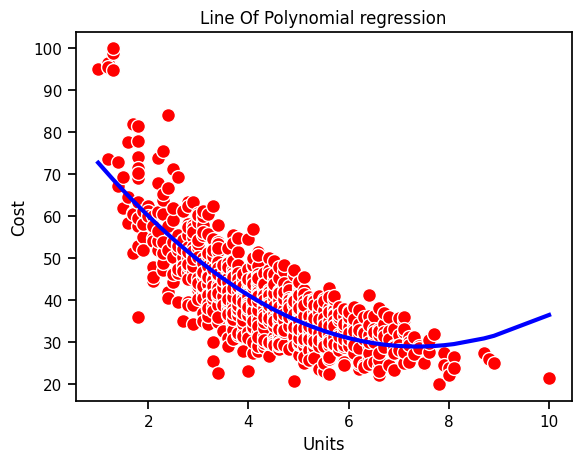

In [28]:
y_pred = lr.predict(x)

sns.scatterplot(
    x= df["Units"],
    y= df["Cost"],
    marker = 'o',
    color = 'red',
    edgecolor = 'white',
    linewidth = 1,
    s  = 100,
    
)

plt.plot(df["Units"], y_pred, color = 'blue', linewidth = 3)
plt.title("Line Of Polynomial regression")
plt.show()